

# Lab 1: Telco Customer Churn Analysis

## 1. Introduction

This lab focuses on analyzing customer churn in a telecommunications company using Python and data analysis techniques. The Telco Customer Churn dataset is loaded into a Pandas DataFrame and examined to understand its structure and attributes.

Data preprocessing is performed by inspecting and converting data types, encoding the Churn attribute into numerical values, and identifying and removing attributes containing missing values.

Data exploration is then conducted to investigate the relationship between customer churn and selected demographic, service, and payment-related attributes. These include gender, senior citizen status, partner status, dependent status, phone service, contract type, paperless billing, and payment method.

The results of each analysis are interpreted to identify patterns and differences in customer churn across the selected categories.



## 2. Dataset Loading

The Telco Customer Churn dataset is loaded into a Pandas DataFrame for inspection and further analysis. Pandas provides tools for reading and manipulating tabular data.


In [1]:

import pandas as pd

file_path = "/kaggle/input/datasets/mukaberayvonne/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)


Dataset loaded successfully.
Dataset shape: (7043, 21)



### 3.1 Displaying the First Five Rows

The `head()` function displays the first five rows of the dataset. It helps us inspect the column names, observe sample customer records, and understand how the data is organized.


In [2]:

df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



**Interpretation:**

The output displays the first five customer records in the dataset. Each row represents a customer, and each column represents an attribute such as gender, tenure, services, contract, payment method, or churn status. This initial inspection helps us understand the dataset's structure before preprocessing.



### 2.2 Displaying the Last Five Rows

The `tail()` function displays the last five rows of the dataset. It helps us inspect records at the end of the dataset and check that the data has been loaded correctly.


In [3]:

df.tail()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No



**Interpretation:**

The output displays the last five customer records in the dataset. It provides a view of the records at the end of the file and helps confirm that the dataset was read through to its final rows.



## 4. Data Preprocessing

Data preprocessing prepares the dataset for analysis by examining data types, converting values into suitable formats, and identifying missing values.

### 4.1 Displaying Data Types

Each attribute has a data type that determines how its values are stored and processed. The `dtypes` attribute helps identify whether columns contain integers, decimal numbers, or text.


In [4]:

df.dtypes


customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


**Interpretation:**

The output shows that most categorical attributes, such as `gender`, `Partner`, `Contract`, and `PaymentMethod`, have the `object` data type. `SeniorCitizen` and `tenure` are stored as integers, while `MonthlyCharges` is stored as a floating-point number.

The `customerID` attribute is stored as `object`, which is appropriate because it is an identifier rather than a numerical measurement. However, `TotalCharges` is also stored as `object`, although it represents a numerical amount. It therefore needs further inspection and conversion to a numerical data type. The `Churn` attribute is stored as `object` and will be converted from `Yes` and `No` to `1` and `0` during preprocessing.



### 4.2 Converting the Churn Attribute

The `Churn` attribute indicates whether a customer has left the telecommunications company. In this step, the values `Yes` and `No` are converted to `1` and `0`, respectively, to represent customer churn numerically.


In [5]:

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print(df["Churn"].value_counts())
print("\nData type:", df["Churn"].dtype)


Churn
0    5174
1    1869
Name: count, dtype: int64

Data type: int64



**Interpretation:**

The `Churn` attribute has been converted from categorical values to numerical values, where `1` represents customers who left the company and `0` represents customers who stayed. The value counts show the number of customers in each category, while the data type confirms that the attribute is now numerical.



### Displaying and Changing Attribute Data Types

In this step, we display the data type of each attribute and change data types where necessary. Categorical attributes are kept as objects, numerical attributes are stored as appropriate numeric types, and the customer identifier remains an object. The `Churn` attribute is represented numerically, with 1 indicating Yes and 0 indicating No.


In [6]:

print("Data types before conversion:")
print(df.dtypes)


Data types before conversion:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                 int64
dtype: object


In [7]:

# Convert TotalCharges from object to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Data types after conversion:")
print(df.dtypes)


Data types after conversion:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object



**Interpretation:**

The output shows that categorical attributes, such as `gender`, `Partner`, `Dependents`, and `PaymentMethod`, are stored as `object`. The `SeniorCitizen` and `tenure` attributes are stored as `int64`, while `MonthlyCharges` and `TotalCharges` are stored as `float64`, making them suitable for numerical operations. The `customerID` attribute remains an object because it identifies customers rather than representing a numerical quantity. The `Churn` attribute is stored as `int64` after converting Yes to 1 and No to 0. Therefore, the attributes now have appropriate data types for further analysis.



### 4.3 Identifying and Removing Attributes with Null Values

Missing values can affect the accuracy and completeness of data analysis. In this step, we identify the attributes containing null values and remove the attributes with missing values from the dataset, as required by the lab instructions.


In [8]:

null_counts = df.isnull().sum()

print("Attributes with null values:")
print(null_counts[null_counts > 0])


Attributes with null values:
TotalCharges    11
dtype: int64



**Interpretation:**

The output identifies `TotalCharges` as an attribute containing 11 missing values. These missing values arose when blank or invalid entries were converted to a numerical format. The attribute must now be handled to satisfy the data preprocessing requirements.


In [9]:

df = df.drop(columns=["TotalCharges"])

print("Dataset shape after removing the attribute:", df.shape)
print("Total null values remaining:", df.isnull().sum().sum())


Dataset shape after removing the attribute: (7043, 20)
Total null values remaining: 0



**Interpretation:**

The `TotalCharges` attribute was removed because it contained missing values. The dataset shape shows the number of rows and columns remaining after removal. The total null-value count is checked to determine whether any missing values remain in the dataset.



## 5. Data Exploration

Data exploration is performed to identify patterns and relationships between customer characteristics and churn. In this section, demographic, service, and payment-related attributes are analyzed to understand how they relate to customer churn.



### 5.1 Demographic Analysis

#### 5.1.1 Gender Distribution Against Churn

This analysis examines the relationship between customer gender and churn status. It compares the number and percentage of male and female customers who stayed with the company and those who left.


Customer counts by gender and churn:


Churn,0,1
gender,,
Female,2549,939
Male,2625,930


Churn percentages by gender:


Churn,0,1
gender,,
Female,73.08,26.92
Male,73.84,26.16


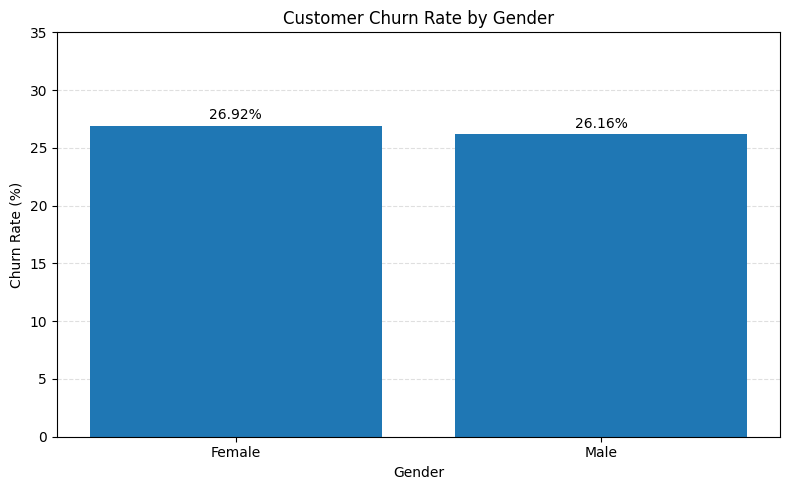

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Check that the dataset is available
if "df" not in globals():
    raise NameError("Run the dataset-loading cell first.")

# Calculate customer counts
gender_counts = pd.crosstab(df["gender"], df["Churn"])

print("Customer counts by gender and churn:")
display(gender_counts)

# Calculate percentages within each gender
gender_percentages = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn percentages by gender:")
display(gender_percentages.round(2))

# Extract churn rates (Churn = 1)
gender_churn_rate = gender_percentages[1]

# Create and display the chart
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    gender_churn_rate.index,
    gender_churn_rate.values
)

ax.set_title("Customer Churn Rate by Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 35)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Add percentages above each bar
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

fig.tight_layout()
plt.show()


**Interpretation:**

The customer counts show that 939 female customers and 930 male customers churned, while 2,549 female customers and 2,625 male customers stayed with the company. The churn rate was 26.92% for female customers and 26.16% for male customers. Therefore, female customers had a slightly higher churn rate than male customers, with a difference of 0.76 percentage points. Overall, the results suggest that gender has only a small observed difference in churn rates in this dataset.



#### 5.1.2 SeniorCitizen and Churn

This analysis examines the relationship between senior citizen status and customer churn. It compares the number and percentage of senior and non-senior customers who stayed with the company and those who left. This helps identify whether churn rates differ according to senior citizen status.


Customer counts by senior citizen status and churn:


Churn,0,1
Non-senior,4508,1393
Senior citizen,666,476


Churn percentages by senior citizen status:


Churn,0,1
Non-senior,76.39,23.61
Senior citizen,58.32,41.68


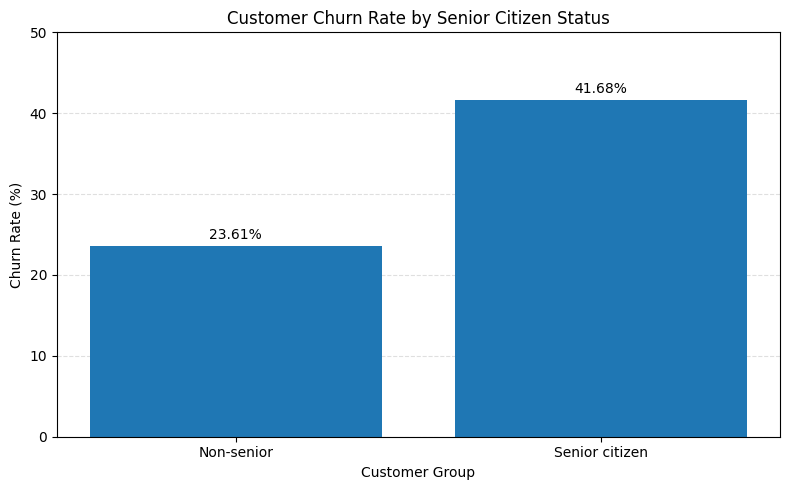

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Customer counts
senior_counts = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"]
)

senior_counts.index = ["Non-senior", "Senior citizen"]

print("Customer counts by senior citizen status and churn:")
display(senior_counts)

# 2. Churn percentages
senior_percentages = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

senior_percentages.index = ["Non-senior", "Senior citizen"]

print("Churn percentages by senior citizen status:")
display(senior_percentages.round(2))

# 3. Plot churn rates
churn_rates = senior_percentages[1]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(churn_rates.index, churn_rates.values)

ax.set_title("Customer Churn Rate by Senior Citizen Status")
ax.set_xlabel("Customer Group")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 50)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Display percentages above bars
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

fig.tight_layout()
plt.show()


**Interpretation:**

The first table shows that 1,393 non-senior customers and 476 senior customers churned. The second table indicates that the churn rate among non-senior customers was 23.61%, compared with 41.68% among senior customers. Therefore, senior customers had a higher churn rate, exceeding the non-senior rate by 18.07 percentage points. This suggests that senior citizen status is associated with a notable difference in customer churn in this dataset.



#### 5.1.3 Partner Status and Churn

This analysis examines the relationship between having a partner and customer churn. It compares the number and percentage of customers with and without partners who stayed with the company and those who left. The aim is to determine whether churn rates differ according to partner status.


Customer counts by partner status and churn:


Churn,0,1
Partner,,
No,2441,1200
Yes,2733,669


Churn percentages by partner status:


Churn,0,1
Partner,,
No,67.04,32.96
Yes,80.34,19.66


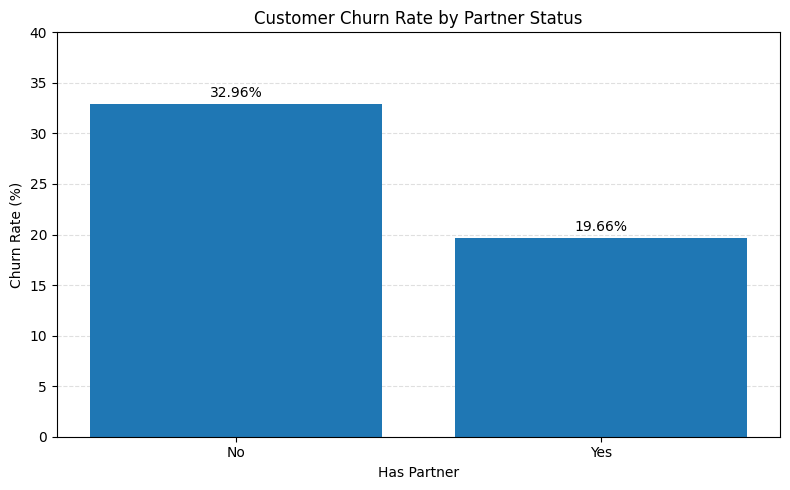

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Customer counts
partner_counts = pd.crosstab(
    df["Partner"],
    df["Churn"]
)

print("Customer counts by partner status and churn:")
display(partner_counts)

# 2. Churn percentages
partner_percentages = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn percentages by partner status:")
display(partner_percentages.round(2))

# 3. Plot churn rates
churn_rates = partner_percentages[1]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(churn_rates.index, churn_rates.values)

ax.set_title("Customer Churn Rate by Partner Status")
ax.set_xlabel("Has Partner")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 40)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Display percentages above bars
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

fig.tight_layout()
plt.show()


**Interpretation:**

The first table shows that 1,200 customers without partners churned, compared with 669 customers with partners. The second table indicates that the churn rate among customers without partners was 32.96%, while customers with partners had a churn rate of 19.66%. Therefore, customers without partners had a higher churn rate by 13.30 percentage points. This suggests that customers without partners were more likely to leave the company than those with partners in this dataset.



#### 5.1.4 Dependents and Churn

This analysis examines the relationship between having dependents and customer churn. It compares the number and percentage of customers with and without dependents who stayed with the company and those who left. The aim is to determine whether churn rates differ according to dependent status.


Customer counts by dependent status and churn:


Churn,0,1
Dependents,,
No,3390,1543
Yes,1784,326


Churn percentages by dependent status:


Churn,0,1
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


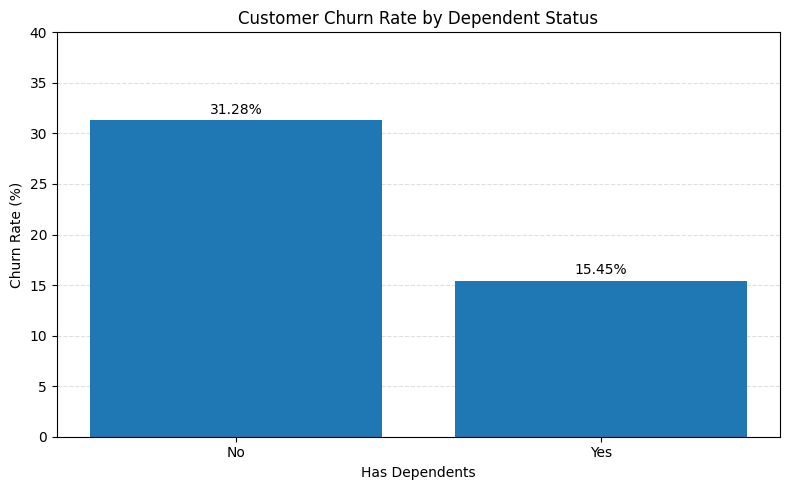

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Customer counts
dependents_counts = pd.crosstab(
    df["Dependents"],
    df["Churn"]
)

print("Customer counts by dependent status and churn:")
display(dependents_counts)

# 2. Churn percentages
dependents_percentages = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn percentages by dependent status:")
display(dependents_percentages.round(2))

# 3. Plot churn rates
churn_rates = dependents_percentages[1]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(churn_rates.index, churn_rates.values)

ax.set_title("Customer Churn Rate by Dependent Status")
ax.set_xlabel("Has Dependents")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 40)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Display percentages above bars
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

fig.tight_layout()
plt.show()


**Interpretation:**

The first table shows that 1,543 customers without dependents churned, compared with 326 customers with dependents. The second table indicates that the churn rate among customers without dependents was 31.28%, while customers with dependents had a churn rate of 15.45%. Therefore, customers without dependents had a higher churn rate by 15.83 percentage points. This suggests that customers without dependents were more likely to leave the company than customers with dependents in this dataset.



### 5.2 Service Analysis

#### 5.2.1 Phone Service Against Churn

This analysis examines the relationship between phone service subscription and customer churn. It compares the number and percentage of customers with and without phone service who stayed with the company and those who left.


Customer counts by phone service and churn:


Churn,0,1
PhoneService,,
No,512,170
Yes,4662,1699


Churn percentages by phone service:


Churn,0,1
PhoneService,,
No,75.07,24.93
Yes,73.29,26.71


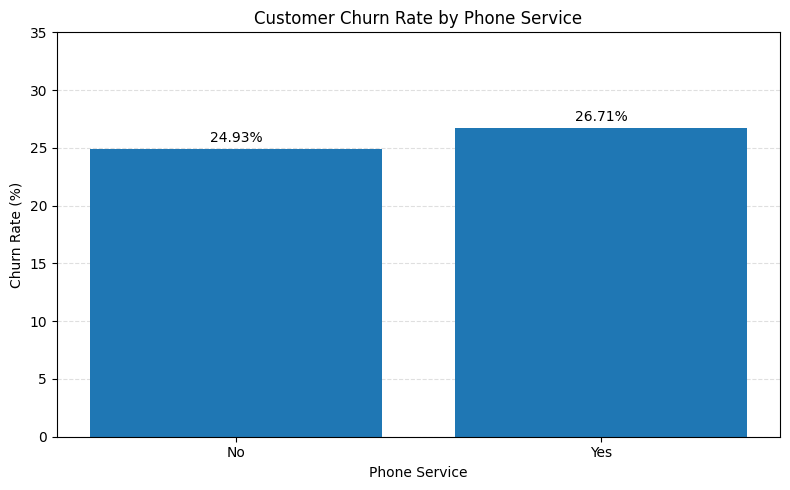

In [14]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Customer counts by phone service and churn
phone_counts = pd.crosstab(df["PhoneService"], df["Churn"])

print("Customer counts by phone service and churn:")
display(phone_counts)

# Churn percentages within each phone service group
phone_percentages = pd.crosstab(
    df["PhoneService"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn percentages by phone service:")
display(phone_percentages.round(2))

# Plot churn rates
churn_rates = phone_percentages[1]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(churn_rates.index, churn_rates.values)

ax.set_title("Customer Churn Rate by Phone Service")
ax.set_xlabel("Phone Service")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 35)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

fig.tight_layout()
plt.show()



**Interpretation:**

The first table shows that 170 customers without phone service churned, compared with 1,699 customers with phone service. The second table indicates that the churn rate was 24.93% among customers without phone service and 26.71% among customers with phone service. Therefore, customers with phone service had a slightly higher churn rate, by 1.78 percentage points. This suggests that phone service subscription is associated with a small difference in churn rates in this dataset.



### 5.3 Payments Analysis

#### 5.3.1 Contract Type and Churn

This analysis examines the relationship between contract type and customer churn. It compares the number and percentage of customers with month-to-month, one-year, and two-year contracts who stayed with the company and those who left.


Customer counts by contract type and churn:


Churn,0,1
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Churn percentages by contract type:


Churn,0,1
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


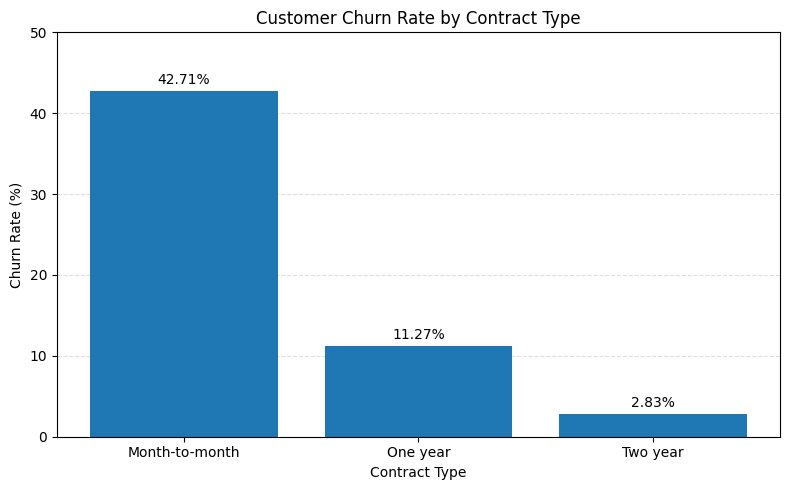

In [15]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Customer counts by contract type and churn
contract_counts = pd.crosstab(df["Contract"], df["Churn"])

print("Customer counts by contract type and churn:")
display(contract_counts)

# Churn percentages within each contract group
contract_percentages = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn percentages by contract type:")
display(contract_percentages.round(2))

# Plot churn rates
churn_rates = contract_percentages[1]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(churn_rates.index, churn_rates.values)

ax.set_title("Customer Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 50)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

fig.tight_layout()
plt.show()



**Interpretation:**

The first table shows the number of customers who stayed with the company and those who churned for each contract type. The second table indicates that month-to-month contracts had the highest churn rate at 42.71%, followed by one-year contracts at 11.27% and two-year contracts at 2.83%. Therefore, customers with month-to-month contracts were much more likely to leave the company than those with longer-term contracts. The results suggest that longer contract commitments are associated with lower customer churn in this dataset.



#### 5.3.2 Paperless Billing and Churn

This analysis examines the relationship between paperless billing and customer churn. It compares the number and percentage of customers who use paperless billing and those who do not, based on whether they stayed with the company or left.


Customer counts by paperless billing and churn:


Churn,0,1
PaperlessBilling,,
No,2403,469
Yes,2771,1400


Churn percentages by paperless billing:


Churn,0,1
PaperlessBilling,,
No,83.67,16.33
Yes,66.43,33.57


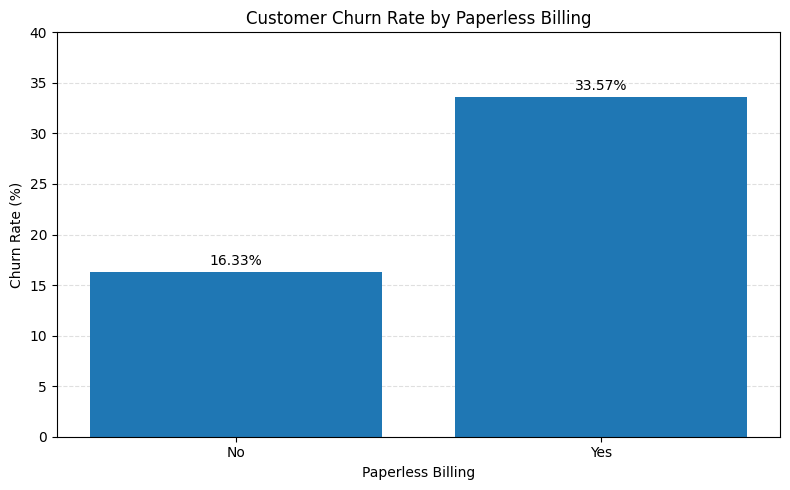

In [16]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Customer counts by paperless billing and churn
billing_counts = pd.crosstab(df["PaperlessBilling"], df["Churn"])

print("Customer counts by paperless billing and churn:")
display(billing_counts)

# Churn percentages within each billing group
billing_percentages = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn percentages by paperless billing:")
display(billing_percentages.round(2))

# Plot churn rates
churn_rates = billing_percentages[1]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(churn_rates.index, churn_rates.values)

ax.set_title("Customer Churn Rate by Paperless Billing")
ax.set_xlabel("Paperless Billing")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 40)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

fig.tight_layout()
plt.show()



**Interpretation:**

The first table shows that 1,400 customers using paperless billing churned, compared with 469 customers who did not use paperless billing. The second table indicates that the churn rate among paperless billing users was 33.57%, while the rate among customers not using paperless billing was 16.33%. Therefore, paperless billing users had a higher churn rate by 17.24 percentage points. This suggests that paperless billing status is associated with a notable difference in customer churn in this dataset.



#### 5.3.3 Payment Method and Churn

This analysis examines the relationship between payment method and customer churn. It compares the number and percentage of customers using each payment method who stayed with the company and those who left.


Customer counts by payment method and churn:


Churn,0,1
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


Churn percentages by payment method:


Churn,0,1
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


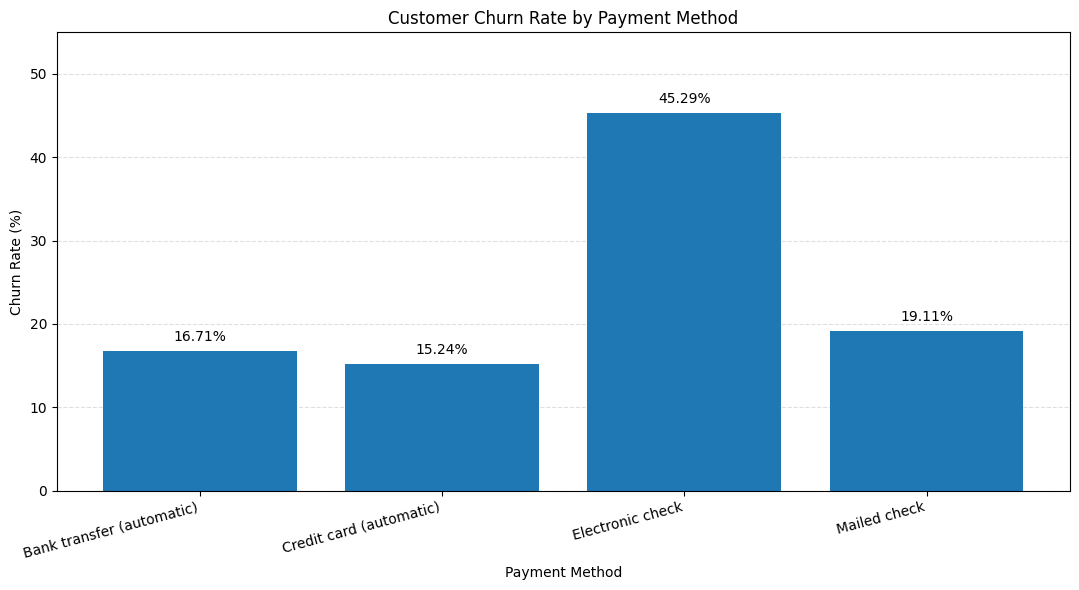

In [17]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Display customer counts by payment method and churn
payment_counts = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"]
)

print("Customer counts by payment method and churn:")
display(payment_counts)

# 2. Calculate churn percentages for each payment method
payment_percentages = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn percentages by payment method:")
display(payment_percentages.round(2))

# 3. Extract the churn rates (Churn = 1)
churn_rates = payment_percentages[1]

# 4. Create a vertical bar chart
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    churn_rates.index,
    churn_rates.values
)

ax.set_title("Customer Churn Rate by Payment Method")
ax.set_xlabel("Payment Method")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 55)

# Keep the chart upright and rotate only the long labels
plt.xticks(rotation=15, ha="right")

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# 5. Display the churn percentage above each bar
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()



**Interpretation:**

The first table shows the number of customers who stayed with the company and those who churned for each payment method. The second table indicates that electronic check users had the highest churn rate at 45.29%, followed by mailed check users at 19.11%, automatic bank transfer users at 16.71%, and automatic credit card users at 15.24%. Therefore, customers using electronic checks were considerably more likely to leave the company than customers using other payment methods. Automatic credit card users had the lowest churn rate. These results suggest that payment method is associated with differences in customer churn in this dataset.



## 6. Conclusion

In this lab, I used Python and Pandas to explore the Telco Customer Churn dataset and investigate factors associated with customers leaving the company. After preprocessing the data, I analyzed eight attributes related to customer demographics, phone service, contracts, and payment methods.

The results showed that some customer groups had noticeably higher churn rates than others. Senior citizens had a churn rate of 41.68%, compared with 23.61% among non-senior customers. Customers without partners and those without dependents also had higher churn rates than their respective comparison groups. Contract type showed an especially clear difference: customers with month-to-month contracts had a churn rate of 42.71%, while the rate for two-year contracts was only 2.83%. Payment method also showed a substantial difference, with electronic check users having the highest churn rate at 45.29%. Paperless billing users had a higher churn rate than customers who did not use paperless billing, whereas gender and phone service showed relatively small differences in churn rates.

Overall, this analysis helped me understand how data exploration can reveal patterns in customer behavior. These findings could help a telecommunications company identify customer groups that may need more attention and develop strategies to improve customer retention. However, the results show associations rather than proving that these attributes directly cause customers to leave.
